In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from math import radians, sin, cos, sqrt, atan2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [2]:
df = pd.read_csv("uber.csv")

In [3]:
print(df.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [4]:
print(df.shape)

(200000, 9)


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None


In [6]:
print(df.describe())

         Unnamed: 0    fare_amount  pickup_longitude  pickup_latitude  \
count  2.000000e+05  200000.000000     200000.000000    200000.000000   
mean   2.771250e+07      11.359955        -72.527638        39.935885   
std    1.601382e+07       9.901776         11.437787         7.720539   
min    1.000000e+00     -52.000000      -1340.648410       -74.015515   
25%    1.382535e+07       6.000000        -73.992065        40.734796   
50%    2.774550e+07       8.500000        -73.981823        40.752592   
75%    4.155530e+07      12.500000        -73.967154        40.767158   
max    5.542357e+07     499.000000         57.418457      1644.421482   

       dropoff_longitude  dropoff_latitude  passenger_count  
count      199999.000000     199999.000000    200000.000000  
mean          -72.525292         39.923890         1.684535  
std            13.117408          6.794829         1.385997  
min         -3356.666300       -881.985513         0.000000  
25%           -73.991407        

In [7]:
df = df.drop(['Unnamed: 0', 'key'], axis=1)

In [8]:
print(df.isnull().sum())

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [9]:
df = df.dropna()

In [10]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

In [11]:
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['dayofweek'] = df['pickup_datetime'].dt.dayofweek

In [12]:
def haversine_distance(lat1, lon1, lat2, lon2):

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (sin(dlat / 2) ** 2 +
         cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2)

    a = max(0, min(1, a))

    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return 6371 * c

In [13]:
df['distance_km'] = df.apply(
    lambda row: haversine_distance(
        row['pickup_latitude'],
        row['pickup_longitude'],
        row['dropoff_latitude'],
        row['dropoff_longitude']
    ),
    axis=1
)

print(df[['pickup_latitude', 'pickup_longitude',
          'dropoff_latitude', 'dropoff_longitude',
          'distance_km']].head())


   pickup_latitude  pickup_longitude  dropoff_latitude  dropoff_longitude  \
0        40.738354        -73.999817         40.723217         -73.999512   
1        40.728225        -73.994355         40.750325         -73.994710   
2        40.740770        -74.005043         40.772647         -73.962565   
3        40.790844        -73.976124         40.803349         -73.965316   
4        40.744085        -73.925023         40.761247         -73.973082   

   distance_km  
0     1.683323  
1     2.457590  
2     5.036377  
3     1.661683  
4     4.475450  


In [14]:
df = df.drop('pickup_datetime', axis=1)

In [15]:
df = df[df['fare_amount'] > 0]

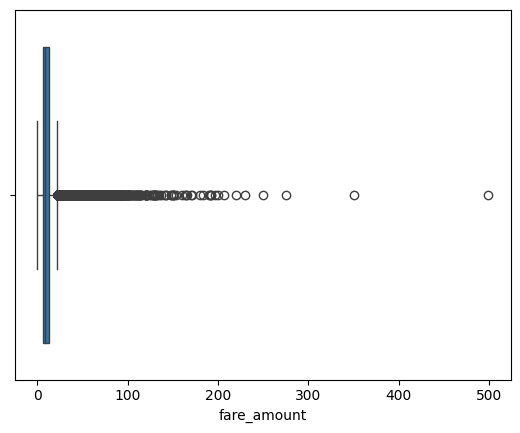

In [16]:
sns.boxplot(x=df['fare_amount'])
plt.show()

In [17]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['fare_amount'] < lower) |
    (df['fare_amount'] > upper)
]


In [18]:
print("Number of outliers:", len(outliers))

Number of outliers: 17155


In [19]:
df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]

In [20]:
correlation = df.corr(numeric_only=True)
print(correlation)



                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000425         0.002573   
pickup_longitude      0.000425          1.000000        -0.812017   
pickup_latitude       0.002573         -0.812017         1.000000   
dropoff_longitude    -0.002299          0.835992        -0.767133   
dropoff_latitude      0.000466         -0.850629         0.684576   
passenger_count       0.012618         -0.000836        -0.001537   
hour                 -0.013291          0.003576        -0.004701   
day                   0.006790          0.003153        -0.006694   
month                 0.026218         -0.003912         0.004124   
year                  0.135414          0.009727        -0.009786   
dayofweek             0.020125         -0.000495        -0.000731   
distance_km           0.002766          0.098303        -0.049154   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                

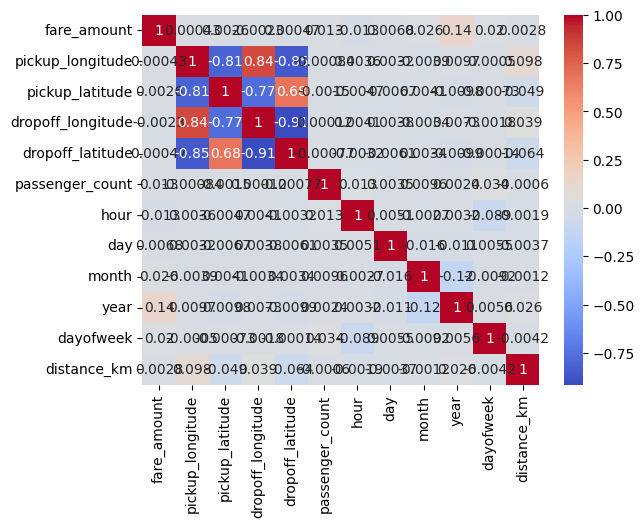

In [21]:
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.show()

In [22]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

In [23]:
print("\nLinear Regression Results:")
print("R2:", r2_lr)
print("RMSE:", rmse_lr)
print("MAE:", mae_lr)


Linear Regression Results:
R2: 0.02043468020215944
RMSE: 4.13240013609468
MAE: 3.273892803968004


In [24]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

print("Random Forest training started...")

rf.fit(X_train, y_train)

print("Random Forest training completed!")

y_pred_rf = rf.predict(X_test)

print("Random Forest prediction completed!")



Random Forest training started...
Random Forest training completed!
Random Forest prediction completed!


In [25]:
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)


In [26]:
print("\nRandom Forest Results:")
print("R2:", r2_rf)
print("RMSE:", rmse_rf)
print("MAE:", mae_rf)


Random Forest Results:
R2: 0.7609678599369287
RMSE: 2.0413328124876147
MAE: 1.3902240559429933


In [27]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2': [r2_lr, r2_rf],
    'RMSE': [rmse_lr, rmse_rf],
    'MAE': [mae_lr, mae_rf]
})


print("MODEL COMPARISON")

print(results.to_string(index=False))

MODEL COMPARISON
            Model       R2     RMSE      MAE
Linear Regression 0.020435 4.132400 3.273893
    Random Forest 0.760968 2.041333 1.390224
